# Random Forest para clasificar dígitos (digits) de SKLearn

Implementar Random Forest para el dataset *digits* de sklearn y encontrar el **mínimo número de árboles**, del **menor tamaño posible**, que ofrezca el mejor rendimiento **sin over-fitting**.

**Integrantes:**
* Isabella Arrieta
* Natalia Carpintero
* Paula Núñez

## 1. Librerías

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

SEMILLA = 42 

## 2. Cargar y dividir el dataset en 80% para entrenamiento y 20% para prueba.  

Se cargan todas las imágenes 'X' de los dígitos , donde cada una indica qué tan oscuro es un punto según 8x8 pixeles. También se cargan las respuesta 'y' que indica qué digito (0-9) es cada imagen. Esto sale del dataset 'digits' de SKLearn

In [17]:
X, y = load_digits(return_X_y=True) # importar dataset digits de sklearn.datasets

# imágenes y respuestas para entrenar y probar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA # 0.2 test - 0.8 train
)

# shape: filas / columnas
print("Dataset completo:", X.shape)
print("Datos de Entrenamiento: ", X_train.shape)
print("Datos de Prueba:", X_test.shape)

Dataset completo: (1797, 64)
Datos de Entrenamiento:  (1437, 64)
Datos de Prueba: (360, 64)


Dibujando las 10 primeras imágenes del dataset (10 dígitos) como una referencia:

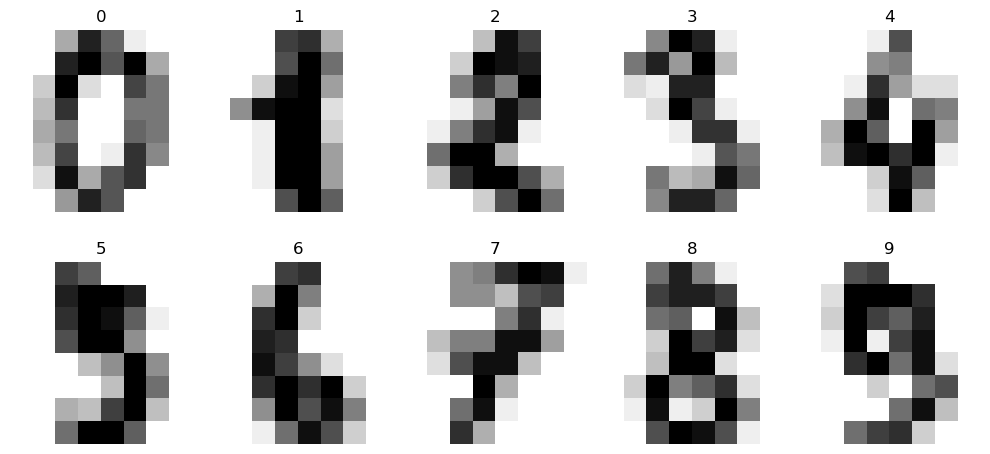

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, imagen, etiqueta in zip(axes.ravel(), X[:10], y[:10]):
    ax.imshow(imagen.reshape(8, 8), cmap="gray_r")  # cada fila de 64 valores vuelve a ser una imagen 8×8
    ax.set_title(etiqueta)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Estrategia de poda: `ccp_alpha` (poda por costo-complejidad)

En el repositorio https://github.com/eduardozurek/ia/blob/main/_007_aprendizaje_supervisado/_007_arboles_de_decision/_007_01_ccp_alpha_DecisionTreeClassifier.ipynb tenemos una explicación del parámetro ccp_alpha

`ccp_alpha` define cuánto tiene que aportar una rama para que valga la pena conservarla, entonces entre mayor sea más se van descartando los subárboles que no aporten, lo cual resulta en **árboles más pequeños**.
No puede ser muy grande ni muy pequeño, porque esto podría ser under-fitting u over-fitting respectivamente.


Primero se construye el árbol y luego se podan los subárboles. 

En lugar de probar valores arbitrarios, se obtienen con `cost_complexity_pruning_path` sobre un árbol entrenado con los datos de entrenamiento. Esto da los valores de $\alpha$ en los que el árbol cambia de tamaño. Se toman 12 valores espaciados a lo largo de ese camino (se excluye el último, que deja solo la raíz al ser ccp_alpha=0).


In [19]:
arbol = DecisionTreeClassifier(random_state=SEMILLA) # crear árbol de decisión
camino = arbol.cost_complexity_pruning_path(X_train, y_train) # lista de valores de ccp_alpha de las que menos a las que más aportan, para podar después.
alphas = camino.ccp_alphas[:-1]  # se quita el último valor porque ese poda todo el árbol

print("Número de alphas en el camino de poda:", len(alphas))

indices = np.unique(np.linspace(0, len(alphas) - 1, 12).astype(int)) # repartir 12 posiciones equidistantes
ccp_alphas = alphas[indices] # alphas en esas posiciones
print("Candidatos de ccp_alpha:", ", ".join(f"{a:.5f}" for a in ccp_alphas))

Número de alphas en el camino de poda: 122
Candidatos de ccp_alpha: 0.00000, 0.00070, 0.00104, 0.00111, 0.00136, 0.00186, 0.00244, 0.00277, 0.00373, 0.00638, 0.01382, 0.05829


Se obtuvieron 122 niveles de poda posibles, y se escogen 12 de forma pareja a lo largo de esa lista para cubrir todo el rango y aumentar las posibilidades de escoger el mejor candidato.

### Árbol base (punto de partida)

Antes de construir el bosque, se entrena **un solo árbol sin poda** para ver el problema que se quiere resolver. Se mide de dos formas:
- Con **validación cruzada K-fold (K = 4)** sobre el conjunto de entrenamiento (80%), se entrena con 3 de las 4 partes y se evalúa con la que quedó afuera, rotando 4 veces, para ver cuánto acierta el árbol con imágenes que no usó para aprender.
- Con el **conjunto de prueba** (20%), solo como referencia (no se usa para elegir nada).

Si la exactitud de entrenamiento es mucho mayor que la de validación o prueba, el árbol está memorizando: **over-fitting**. Esto es lo que estamos intentando evitar.

In [20]:
arbol.fit(X_train, y_train) # entrena el árbol con el 80%

# cuando hablamos de acertar se refiere a clasificar el dígito correcto según la imagen
acc_train_base = arbol.score(X_train, y_train) # cuánto acierta con las mismas imágenes con que aprendió 
acc_test_base = arbol.score(X_test, y_test) # cuánto acierta con los datos de prueba (20% que no vio antes)

print(f"Exactitud del árbol base en entrenamiento: {acc_train_base:.4f}")
print(f"Exactitud del árbol base en prueba: {acc_test_base:.4f}")
print(f"Brecha entre entrenamiento y prueba: {acc_train_base - acc_test_base:.4f}")
print(f"Profundidad del árbol: {arbol.get_depth()}")
print(f"Número de hojas del árbol: {arbol.get_n_leaves()}")

Exactitud del árbol base en entrenamiento: 1.0000
Exactitud del árbol base en prueba: 0.8250
Brecha entre entrenamiento y prueba: 0.1750
Profundidad del árbol: 14
Número de hojas del árbol: 142


Estos datos nos dicen:
* Acierta en el 100% de imágenes que ya vio
* Acierta en el 82.5% de imágenes nuevas
* Lo anterior da una brecha de 0.175: over-fitting debido a que memorizó las imágenes de entrenamiento y no aprendió la forma general de los dígitos.
* Profundidad 14 y 142 hojas: se trata de un árbol base grande. Necesitamos árboles del menor tamaño posible.

In [21]:
kfold = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA)  # K-fold = 4

res_base = cross_validate(arbol, X_train, y_train, cv=kfold, return_train_score=True, scoring="accuracy") # ir rotando para validar con cada parte (fold)

for i, (tr, va) in enumerate(zip(res_base["train_score"], res_base["test_score"]), start=1):
    print(f"Fold {i}: entrenamiento {tr:.4f} | validación {va:.4f}")

print()
print(f"Entrenamiento promedio: {res_base['train_score'].mean():.4f}")
print(f"Validación promedio:    {res_base['test_score'].mean():.4f} ± {res_base['test_score'].std():.4f}")
print(f"Brecha promedio:        {res_base['train_score'].mean() - res_base['test_score'].mean():.4f}")

Fold 1: entrenamiento 1.0000 | validación 0.8389
Fold 2: entrenamiento 1.0000 | validación 0.8607
Fold 3: entrenamiento 1.0000 | validación 0.8524
Fold 4: entrenamiento 1.0000 | validación 0.8468

Entrenamiento promedio: 1.0000
Validación promedio:    0.8497 ± 0.0080
Brecha promedio:        0.1503


Acá usamos el k-fold en el árbol base. En cada rotación, el árbol acierta el 100% de las imágenes con que entrenó, pero solo un promedio de 84.97% de las imágenes de validación, que no había visto.

## 4. Búsqueda con validación cruzada K-fold (K = 4)

Se busca la mejor combinación de cuántos árboles y cuánta poda para el bosque:
- `n_estimators` (número de árboles): 15 valores entre 1 y 300.
- `ccp_alpha` (nivel de poda): los 12 candidatos.

Son 15 * 12 = 180 bosques. Cada uno se evalúa con K-fold (las mismas 4 partes del árbol base), guardando la exactitud de entrenamiento y de validación para medir el over-fitting.



In [22]:
parametros = { # probar varios tamaños de bosque y niveles de poda
    "n_estimators": [1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200, 300],
    "ccp_alpha": ccp_alphas, # niveles de poda
}

busqueda = GridSearchCV(
    RandomForestClassifier(random_state=SEMILLA),
    param_grid=parametros,
    cv=kfold,
    scoring="accuracy",
    return_train_score=True,
    refit=False, 
    n_jobs=1,
)
busqueda.fit(X_train, y_train); # entrenar (80%) para los 4 folds de cada bosque
print("Búsqueda terminada:", len(busqueda.cv_results_["params"]), "combinaciones evaluadas")

Traceback (most recent call last):
  File "/nix/store/fn09pmy22pb71vngw05ni5hgw62rhya1-python3-3.13.12-env/lib/python3.13/multiprocessing/resource_tracker.py", line 371, in main
    raise ValueError(
        f'Cannot register {name} for automatic cleanup: '
        f'unknown resource type {rtype}')
ValueError: Cannot register /loky-10565-jd41cto8 for automatic cleanup: unknown resource type semlock
Traceback (most recent call last):
  File "/nix/store/fn09pmy22pb71vngw05ni5hgw62rhya1-python3-3.13.12-env/lib/python3.13/multiprocessing/resource_tracker.py", line 371, in main
    raise ValueError(
        f'Cannot register {name} for automatic cleanup: '
        f'unknown resource type {rtype}')
ValueError: Cannot register /loky-10565-17nv4xr1 for automatic cleanup: unknown resource type semlock
Traceback (most recent call last):
  File "/nix/store/fn09pmy22pb71vngw05ni5hgw62rhya1-python3-3.13.12-env/lib/python3.13/multiprocessing/resource_tracker.py", line 371, in main
    raise ValueErr

Búsqueda terminada: 180 combinaciones evaluadas


## 5. Resultados de la validación cruzada y over-fitting.

Exactitud de validación para cada combinación de número de árboles y nivel de poda:

In [23]:
res = pd.DataFrame(busqueda.cv_results_)
res = pd.DataFrame({
    "n_estimators": res["param_n_estimators"].astype(int),
    "ccp_alpha": res["param_ccp_alpha"].astype(float),
    "acc_entrenamiento": res["mean_train_score"],
    "acc_validacion": res["mean_test_score"],
    "std_validacion": res["std_test_score"],
})
res["brecha"] = res["acc_entrenamiento"] - res["acc_validacion"]

print("Exactitud de validación (filas: ccp_alpha, columnas: n_estimators)")
tabla = res.pivot(index="ccp_alpha", columns="n_estimators", values="acc_validacion")
tabla.index = np.round(tabla.index, 5)
tabla.round(3)

Exactitud de validación (filas: ccp_alpha, columnas: n_estimators)


n_estimators,1,5,10,20,30,40,50,60,70,80,90,100,150,200,300
ccp_alpha,,,,,,,,,,,,,,,
0.00000,0.773,0.900,0.941,0.964,0.965,0.967,0.967,0.969,0.969,0.969,0.971,0.972,0.971,0.976,0.973
0.00070,0.773,0.901,0.942,0.962,0.965,0.968,0.966,0.967,0.969,0.969,0.971,0.972,0.971,0.976,0.974
0.00104,0.776,0.902,0.940,0.960,0.968,0.967,0.966,0.967,0.969,0.970,0.970,0.972,0.969,0.972,0.972
0.00111,0.777,0.901,0.941,0.960,0.968,0.967,0.966,0.967,0.969,0.969,0.970,0.972,0.969,0.972,0.971
0.00136,0.777,0.904,0.939,0.962,0.968,0.965,0.967,0.965,0.968,0.969,0.969,0.971,0.969,0.972,0.971
0.00186,0.784,0.905,0.937,0.958,0.959,0.961,0.964,0.965,0.966,0.968,0.967,0.970,0.971,0.973,0.973
0.00244,0.781,0.903,0.940,0.958,0.961,0.958,0.962,0.964,0.965,0.965,0.967,0.970,0.970,0.971,0.969
0.00277,0.779,0.897,0.937,0.956,0.960,0.961,0.964,0.963,0.964,0.964,0.966,0.968,0.966,0.970,0.967
0.00373,0.766,0.889,0.930,0.947,0.955,0.956,0.960,0.961,0.960,0.962,0.960,0.960,0.960,0.963,0.960


Representación gráfica:

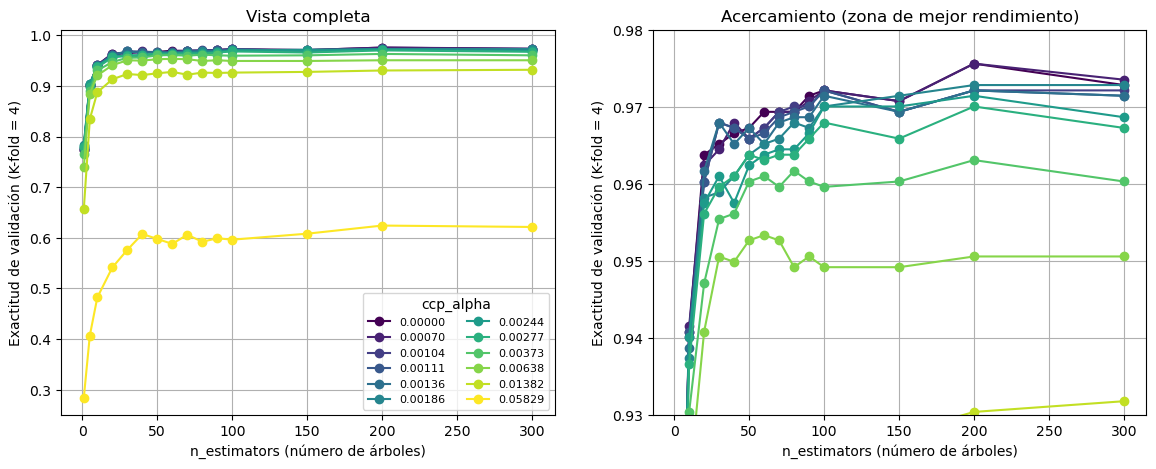

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = plt.cm.viridis(np.linspace(0, 1, len(ccp_alphas)))
for ax, titulo in zip(axes, ["Vista completa", "Acercamiento (zona de mejor rendimiento)"]):
    for color, (a, grupo) in zip(colores, res.groupby("ccp_alpha")):
        ax.plot(grupo["n_estimators"], grupo["acc_validacion"], marker="o", color=color, label=f"{a:.5f}")
    ax.set_xlabel("n_estimators (número de árboles)")
    ax.set_ylabel("Exactitud de validación (K-fold = 4)")
    ax.set_title(titulo)
    ax.grid(True)
axes[1].set_ylim(0.93, 0.98)
axes[0].legend(title="ccp_alpha", fontsize=8, ncol=2)
plt.show()

Con pocos árboles la exactitud sube rápido, pero desde unos 50 árboles casi no mejora. Podar poco (líneas oscuras) mantiene la exactitud en ~0.97; podar mucho la baja, hasta ~0.60 con la poda máxima (línea amarilla). El pico de exactitud en 200 árboles es una variación pequeña, así que se buscará el bosque más pequeño que rinda igual.

## 6. Criterio de selección: mínimo número de árboles, del menor tamaño, sin over-fitting

El enunciado pide el **mínimo número de árboles**, **del menor tamaño posible**, con los **mejores indicadores de rendimiento** y **sin over-fitting**. 

1. **Mejor rendimiento:** se identifica la combinación con mayor exactitud de validación y se aceptan también las que están a no más de una desviación estándar de ella.
2. **Sin over-fitting:** se descartan las combinaciones con brecha entre entrenamiento y validación mayor a 0.05.
3. **Mínimo número de árboles:** entre las que quedan, se elige el menor 'n_estimators'.
4. **Menor tamaño de árbol:** con ese número de árboles, se elige el más podado.

In [ ]:
MAX_BRECHA = 0.05

mejor = res.loc[res["acc_validacion"].idxmax()]
umbral = mejor["acc_validacion"] - mejor["std_validacion"]

print(f"Mejor combinación: n_estimators={int(mejor['n_estimators'])}, "
      f"ccp_alpha={mejor['ccp_alpha']:.5f}, "
      f"acc_validacion={mejor['acc_validacion']:.4f} ± {mejor['std_validacion']:.4f}")
print(f"Umbral de exactitud aceptable: {umbral:.4f}")

candidatos = res[(res["acc_validacion"] >= umbral) & (res["brecha"] <= MAX_BRECHA)]
candidatos = candidatos.sort_values(["n_estimators", "ccp_alpha"], ascending=[True, False])

elegido = candidatos.iloc[0]
N_ARBOLES = int(elegido["n_estimators"])
ALPHA = float(elegido["ccp_alpha"]) # CCP_ALPHA ELEGIDO

print(f"\nCombinación elegida: n_estimators={N_ARBOLES}, ccp_alpha={ALPHA:.5f}")
print(f"acc_validacion={elegido['acc_validacion']:.4f}, brecha={elegido['brecha']:.4f}")

candidatos.head(10).round(4)

Mejor combinación: n_estimators=200, ccp_alpha=0.00000, acc_validacion=0.9756 ± 0.0050
Umbral de exactitud aceptable: 0.9707

Combinación elegida: n_estimators=90, ccp_alpha=0.00070
acc_validacion=0.9708, brecha=0.0292


,n_estimators,ccp_alpha,acc_entrenamiento,acc_validacion,std_validacion,brecha
25,90,0.0007,1.0000,0.9708,0.0046,0.0292
10,90,0.0000,1.0000,0.9715,0.0036,0.0285
71,100,0.0014,1.0000,0.9715,0.0041,0.0285
56,100,0.0011,1.0000,0.9722,0.0034,0.0278
41,100,0.0010,1.0000,0.9722,0.0034,0.0278
26,100,0.0007,1.0000,0.9722,0.0028,0.0278
11,100,0.0000,1.0000,0.9722,0.0028,0.0278
87,150,0.0019,0.9998,0.9715,0.0030,0.0283
27,150,0.0007,1.0000,0.9708,0.0024,0.0292
12,150,0.0000,1.0000,0.9708,0.0024,0.0292


El mejor resultado lo obtuvo un bosque de 200 árboles sin poda (0.9756 ± 0.0050), así que se consideran equivalentes los que lleguen al menos a 0.9707. Ningún bosque de menos de 90 árboles alcanza ese nivel. Con 90 árboles hay dos opciones, y se elige la más podada: **90 árboles con `ccp_alpha` = 0.0007**, con una exactitud de 0.9708 y una brecha de 0.029, así que no hay over-fitting.

## 7. Efecto de la poda en el tamaño de los árboles

Para mostrar cómo `ccp_alpha` reduce el tamaño de los árboles, se entrena un bosque con el número de árboles elegido para cada `ccp_alpha` candidato y se mide el promedio de **nodos** y de **profundidad** de sus árboles, junto con la exactitud de validación obtenida en la sección 4.

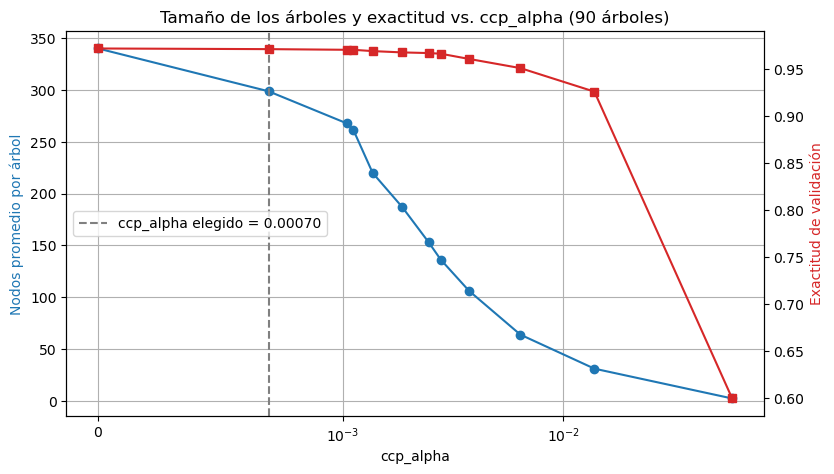

,ccp_alpha,nodos_promedio,profundidad_promedio,acc_validacion
0,0.0000,340.1333,13.2889,0.9715
1,0.0007,298.8000,12.7444,0.9708
2,0.0010,267.6889,12.3667,0.9701
3,0.0011,261.6000,12.3333,0.9701
4,0.0014,219.9778,11.8444,0.9687
5,0.0019,187.0000,11.4778,0.9673
6,0.0024,153.0667,10.7889,0.9666
7,0.0028,136.2667,10.4667,0.9659
8,0.0037,106.0222,9.7444,0.9603
9,0.0064,63.7778,8.2333,0.9506


In [26]:
filas = []
for a in ccp_alphas:
    rf = RandomForestClassifier(n_estimators=N_ARBOLES, ccp_alpha=a, random_state=SEMILLA)
    rf.fit(X_train, y_train)
    acc_val = res[(res["n_estimators"] == N_ARBOLES) & (res["ccp_alpha"] == a)]["acc_validacion"].iloc[0]
    filas.append({
        "ccp_alpha": a,
        "nodos_promedio": np.mean([t.tree_.node_count for t in rf.estimators_]),
        "profundidad_promedio": np.mean([t.get_depth() for t in rf.estimators_]),
        "acc_validacion": acc_val,
    })
tamanos = pd.DataFrame(filas)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(tamanos["ccp_alpha"], tamanos["nodos_promedio"], marker="o", color="tab:blue")
ax1.set_xscale("symlog", linthresh=1e-3)
ax1.set_xlabel("ccp_alpha")
ax1.set_ylabel("Nodos promedio por árbol", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(tamanos["ccp_alpha"], tamanos["acc_validacion"], marker="s", color="tab:red")
ax2.set_ylabel("Exactitud de validación", color="tab:red")
ax1.axvline(ALPHA, color="gray", linestyle="--", label=f"ccp_alpha elegido = {ALPHA:.5f}")
ax1.legend(loc="center left")
ax1.set_title(f"Tamaño de los árboles y exactitud vs. ccp_alpha ({N_ARBOLES} árboles)")
ax1.grid(True)
plt.show()

tamanos.round(4)

Esta gráfica muestra para qué sirve la poda: a medida que se poda más (hacia la derecha), los árboles se hacen más pequeños (línea azul). Al principio eso no afecta los aciertos (la línea roja se mantiene arriba), pero si se poda demasiado, los árboles ya no logran reconocer los dígitos y los aciertos caen. Por eso se elige una poda leve (línea gris): árboles más pequeños sin perder aciertos.

## 8. Modelo final y evaluación en el conjunto de prueba

Se entrena el Random Forest con la combinación elegida usando todo el conjunto de entrenamiento (80 %) y se evalúa por 1ra vez de forma práctica con el conjunto de prueba (20 %). Si la exactitud de prueba es parecida a la de validación, el modelo generaliza y no hay over-fitting.

In [27]:
modelo = RandomForestClassifier(n_estimators=N_ARBOLES, ccp_alpha=ALPHA, random_state=SEMILLA)
modelo.fit(X_train, y_train)

acc_train = accuracy_score(y_train, modelo.predict(X_train))
y_pred = modelo.predict(X_test)
acc_test = accuracy_score(y_test, y_pred)

print(f"Árboles: {N_ARBOLES} | ccp_alpha: {ALPHA:.5f}")
print(f"Nodos promedio por árbol: {np.mean([t.tree_.node_count for t in modelo.estimators_]):.1f}")
print(f"Profundidad promedio:     {np.mean([t.get_depth() for t in modelo.estimators_]):.1f}")
print()
print(f"Exactitud entrenamiento:        {acc_train:.4f}")
print(f"Exactitud validación (K-fold):  {elegido['acc_validacion']:.4f}")
print(f"Exactitud prueba:               {acc_test:.4f}")
print()
print(classification_report(y_test, y_pred, digits=4))

Árboles: 90 | ccp_alpha: 0.00070
Nodos promedio por árbol: 298.8
Profundidad promedio:     12.7

Exactitud entrenamiento:        1.0000
Exactitud validación (K-fold):  0.9708
Exactitud prueba:               0.9611

              precision    recall  f1-score   support

           0     0.9722    0.9722    0.9722        36
           1     0.8974    0.9722    0.9333        36
           2     1.0000    0.9714    0.9855        35
           3     0.9730    0.9730    0.9730        37
           4     0.9722    0.9722    0.9722        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    0.9722    0.9859        36
           7     0.9231    1.0000    0.9600        36
           8     0.9375    0.8571    0.8955        35
           9     0.9706    0.9167    0.9429        36

    accuracy                         0.9611       360
   macro avg     0.9620    0.9607    0.9607       360
weighted avg     0.9620    0.9611    0.9609       360



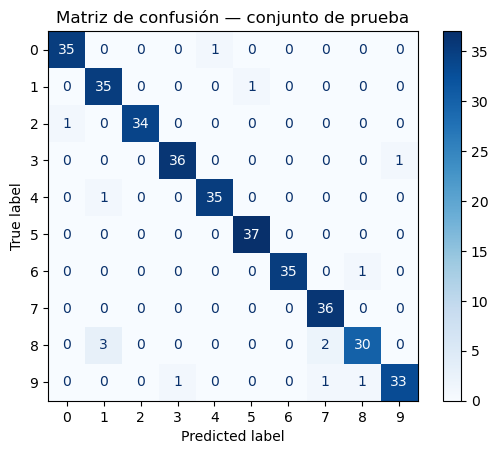

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión - conjunto de prueba")
plt.show()

In [32]:
# Aciertos por dígito: diagonales
aciertos = 35 + 35 + 34 + 36 + 35+ 37+ 35+ 36 + 30 + 33
print(f"Aciertos: {aciertos}")
porcentaje = (346*100)/360
print(f"Porcentaje de aciertos: {porcentaje:.2f}%")

Aciertos: 346
Porcentaje de aciertos: 96.11%


El modelo final acierta 346 de 360 imágenes de prueba (96.1 %), cerca de lo que predijo la validación (97.1 %), así que generaliza bien y no hay over-fitting. El dígito más difícil es el 8 (menos aciertos), que a veces confunde con el 1 y el 7; el resto se reconoce con más del 90 % de acierto.

## 9. Conclusiones

- **Un árbol solo memoriza:** acierta el 100 % de lo que ya vio, pero solo el 82.5 % de imágenes nuevas.
- **La poda achica los árboles:** una poda leve les quita ramas que no aportaban sin perder aciertos; si se poda demasiado, ya no reconocen los dígitos.
- **No hacen falta muchos árboles:** desde unos 50 árboles los aciertos casi no mejoran.
- **Modelo elegido:** 90 árboles con poda leve (`ccp_alpha` = 0.0007), el bosque más pequeño que rinde casi igual que el mejor.
- **No memoriza:** acierta el 96.1 % de las imágenes de prueba, muy cerca del 97.1 % que predijo la validación.
- **El dígito más difícil es el 8,** que a veces confunde con el 1 y el 7.